# Amazon MLP - определение категории товара по названию


**Цель:** классифицировать название товара в одну из категорий: `Electronics`, `Computers&Accessories`, `Home&Kitchen`.

**Датасет:** `amazon.csv` (1 465 строк, 16 столбцов). Используем поля `product_id`, `product_name`, `category`. После фильтрации и удаления повторов - **1 299 товаров**. Три выборки: Train **779**, Validation **260**, Test **260**.


## Импорт библиотек


In [ ]:
import copy
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from torch import nn
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    auc
)
from sklearn.dummy import DummyClassifier


## НАСТРОЙКИ

настраиваем воспроизводимость и параметры обучения.

`SEED=42` фиксирует генераторы случайных чисел. `EPOCHS=200` - предел количества проходов по Train, но Early Stopping может остановить обучение раньше. `BATCH_SIZE=32` определяет число товаров в одном батче, `LEARNING_RATE=0.001` - базовую скорость Adam, `PATIENCE=20` - допустимое число эпох подряд без улучшения Validation Loss.

`device` выбирает CUDA, если поддерживаемый GPU доступен в установленной версии PyTorch, иначе CPU.

In [ ]:
SEED = 42
EPOCHS = 200
BATCH_SIZE = 32
LEARNING_RATE = 0.001
PATIENCE = 20

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Устройство:", device)


## ЗАГРУЗКА ДАННЫХ

загружаем исходный CSV и оставляем только три столбца: `product_id`, `product_name`, `category`.

Из сложной иерархии категорий берём первый компонент (`Electronics`, `Computers&Accessories`, `Home&Kitchen`). Другие категории не изучаем: их слишком мало, чтобы сравнение было устойчивым.

повторяющиеся `product_id` и точные совпадения `product_name` удаляются до разделения. Так одинаковое название не окажется и в Train, и в Test. Но почти одинаковые формулировки одного товара всё ещё могут присутствовать

In [ ]:
csv_path = Path("amazon.csv")
if not csv_path.exists():
    csv_path = Path("upload") / "amazon.csv"
df = pd.read_csv(csv_path)

print("\nИсходный размер:", df.shape)

df = df[
    ["product_id", "product_name", "category"]
].dropna().copy()

# В category хранится длинная цепочка категорий, нужна только первая.
df["main_category"] = (
    df["category"].str.split("|").str[0]
)

categories = [
    "Electronics",
    "Computers&Accessories",
    "Home&Kitchen"
]

df = df[
    df["main_category"].isin(categories)
].copy()

# Один и тот же товар может встречаться несколько раз, оставляю одну хапись
df = df.drop_duplicates(subset="product_id")

# Одинаковые названия тоже убираем иначе модель может увидеть
# одно название и в обучении, и в тесте.
df = df.drop_duplicates(subset="product_name")

# убираем пустые названия
df = df[df["product_name"].astype(str).str.strip() != ""]

print("\nПосле очистки:", df.shape)

print("\nРаспределение категорий:")
print(df["main_category"].value_counts())


## ПОДГОТОВКА X И y

разделяем признаки `X` (названия товаров) и правильные ответы `y` (главные категории).

`LabelEncoder` сопоставляет текстовым категориям целые номера 0, 1, 2. Числа служат метками, а не измерением качества товара. При показе результатов `inverse_transform()` снова возвращает человеку понятные названия.

In [ ]:
# X — названия товаров
X = df["product_name"].astype(str).values

# y — названия категорий
y_text = df["main_category"].values

# Превращаем категории в числа
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_text)

print("\nКлассы:")

for i, name in enumerate(label_encoder.classes_):
    print(i, "=", name)


## TRAIN / VALIDATION / TEST

делим очищенную выборку на Train (~60%), Validation (~20%) и Test (~20%).

Первый `train_test_split` выделяет 40% во временный массив, второй делит его пополам. Параметр `stratify` помогает сохранить доли классов. `random_state` делает разделение воспроизводимым.

Train обновляет веса, Validation служит для выбора лучшей эпохи, Test оставляем для заключительной оценки. 

In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.4,
    random_state=SEED,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    random_state=SEED,
    stratify=y_temp
)

print("\nРазмеры выборок:")
print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))


## ПРЕОБРАЗОВАНИЕ ТЕКСТА В ЧИСЛА

превращаем текст в числовые признаки при помощи TF-IDF.

`max_features=1000` ограничивает словарь; `ngram_range=(1,2)` учитывает одиночные слова и пары соседних слов. TF-IDF учитывает частоту слова в данном названии и его распространённость по всем тренировочным названиям.

`fit_transform()` только для Train. На Validation и Test вызываем только `transform()`, используя тот же словарь и те же статистики IDF. Иначе появится утечка информации из отложенных данных.

In [ ]:
vectorizer = TfidfVectorizer(
    max_features=1000,
    ngram_range=(1, 2),
    lowercase=True
)

# Словарь TF-IDF строим только по обучающей части,
# иначе информация из теста попадёт в подготовку признаков.
X_train_tfidf = vectorizer.fit_transform(X_train)

# Validation и Test преобразуем уже созданным словарём
X_val_tfidf = vectorizer.transform(X_val)
X_test_tfidf = vectorizer.transform(X_test)

print("\nКоличество признаков:",
      X_train_tfidf.shape[1])


##  БАЗОВАЯ МОДЕЛЬ

получаем минимальную точку отсчёта качества - `DummyClassifier(strategy='most_frequent')`.

Он всегда выбирает наиболее частую категорию Train и не изучает текст. Для нашей зафиксированной выборки его Test Accuracy составляет **0.3692**, Macro F1 **0.1798**. Эти показатели можно воспроизвести даже без PyTorch.


In [ ]:
# Для сравнения берём совсем простую модельтак как она всегда
# выбирает самый частый класс из обучающей выборки.
baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(X_train_tfidf, y_train)

baseline_predictions = baseline.predict(X_test_tfidf)

baseline_accuracy = accuracy_score(
    y_test, baseline_predictions
)

baseline_f1 = f1_score(
    y_test,
    baseline_predictions,
    average="macro",
    zero_division=0
)

print("\nBASELINE")
print("Accuracy:", round(baseline_accuracy, 4))
print("Macro F1:", round(baseline_f1, 4))


## ПРЕОБРАЗОВАНИЕ В ТЕНЗОРЫ

создаём тензоры PyTorch и DataLoader.

`X_train_tfidf` - разреженная матрица. `.toarray()` переводит её в плотный NumPy-массив, затем `torch.tensor(..., dtype=torch.float32)` делает числовой тензор для нейросети. Метки категорий имеют тип `torch.long`, как ожидает `CrossEntropyLoss`

`TensorDataset` соединяет признаки и ответы по индексам, а `DataLoader(batch_size=32, shuffle=True)` выдаёт случайно перемешанные батчи. Тензоры, созданные для `train_dataset`, остаются на CPU, в цикле каждый батч переносится на выбранное устройство

In [ ]:
train_x = torch.tensor(
    X_train_tfidf.toarray(),
    dtype=torch.float32
)

val_x = torch.tensor(
    X_val_tfidf.toarray(),
    dtype=torch.float32
)

test_x = torch.tensor(
    X_test_tfidf.toarray(),
    dtype=torch.float32
)

train_y = torch.tensor(
    y_train,
    dtype=torch.long
)

val_y = torch.tensor(
    y_val,
    dtype=torch.long
)

test_y = torch.tensor(
    y_test,
    dtype=torch.long
)

from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(train_x, train_y)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

train_x = train_x.to(device)
val_x = val_x.to(device)
test_x = test_x.to(device)

train_y = train_y.to(device)
val_y = val_y.to(device)
test_y = test_y.to(device)


## СОЗДАНИЕ MLP

 создаём многослойный перцептрон.

Схема: **1000 → 128 → 64 → 3** (при 1000 признаках TF-IDF). Между полносвязными слоями используем `ReLU` и `Dropout(0.2)`. Три выхода - это *logits*

Число обучаемых параметров при 1000 входах: `(1000×128+128) + (128×64+64) + (64×3+3) = 136 579`. ReLU и Dropout обучаемых параметров не имеют. Такой размер сети для 779 тренировочных товаров большой, поэтому важно следить за переобучением.

In [ ]:
input_size = X_train_tfidf.shape[1]
num_classes = len(label_encoder.classes_)

model = nn.Sequential(
    nn.Linear(input_size, 128),
    nn.ReLU(),
    nn.Dropout(0.2),

    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Dropout(0.2),

    nn.Linear(64, num_classes)
).to(device)

print("\nАРХИТЕКТУРА MLP")
print(model)

parameters = sum(
    p.numel() for p in model.parameters()
)

print("Количество параметров:", parameters)


## ОПТИМИЗАТОР И ФУНКЦИЯ ПОТЕРЬ

выбираем Adam с `lr=0.001`, L2-подобной регуляризацией `weight_decay=0.001` и `nn.CrossEntropyLoss()`.

Для классификации каждого товара ровно в один из трёх классов CrossEntropyLoss принимает logits формы `(batch, 3)` и номера классов формы `(batch,)`. oftmax перед CrossEntropyLoss не добавляем, необходимые преобразования уже встроены в эту функцию потерь.

Adam использует текущий градиент и скользящую статистику прошлых градиентов для обновления весов.

In [ ]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0.001
)

loss_fn = nn.CrossEntropyLoss()


## EARLY STOPPING

готовим переменные для Early Stopping.

`best_val_loss=float('inf')` позволяет сохранить первую же оценку. `best_weights = copy.deepcopy(model.state_dict())` создаёт независимую копию весов, без глубокого копирования значения могли бы изменяться вместе с моделью. `train_history`, `val_history`, `accuracy_history` нужны для графиков

In [ ]:
best_val_loss = float("inf")
best_epoch = 0
best_weights = copy.deepcopy(model.state_dict())

epochs_without_improvement = 0

train_history = []
val_history = []
accuracy_history = []


##  ОБУЧЕНИЕ

 выполняем весь цикл обучения

Для каждого батча: `zero_grad()` → `model(batch_x)` → `CrossEntropyLoss` → `backward()` → `optimizer.step()`. После окончания всех батчей одной эпохи переключаемся в `model.eval()` и измеряем Train/Validation без градиентов.

Если Validation Loss достиг нового минимума, сохраняем веса и номер эпохи. Если улучшения нет 20 эпох подряд, цикл останавливается. Validation не используется для вычисления градиентов и прямого обучения весов.

In [ ]:
for epoch in range(EPOCHS):

    model.train()

    for batch_x, batch_y in train_loader:

        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad()

        predictions = model(batch_x)

        loss = loss_fn(predictions, batch_y)

        loss.backward()

        optimizer.step()

    # После каждой эпохи смотрим, как модель ведёт себя
    # на обучающей и проверочной выборках
    model.eval()

    with torch.no_grad():

        train_logits = model(train_x)
        val_logits = model(val_x)

        train_loss = loss_fn(
            train_logits, train_y
        ).item()

        val_loss = loss_fn(
            val_logits, val_y
        ).item()

        val_predictions = torch.argmax(
            val_logits, dim=1
        )

        val_accuracy = (
            (val_predictions == val_y)
            .float().mean().item()
        )

    train_history.append(train_loss)
    val_history.append(val_loss)
    accuracy_history.append(val_accuracy)

    # Если на Validation ошибка стала меньше, запомним эти веса
    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_epoch = epoch + 1

        best_weights = copy.deepcopy(
            model.state_dict()
        )

        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    if (epoch + 1) % 10 == 0:

        print(
            f"Epoch {epoch + 1:3d} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Accuracy: {val_accuracy:.4f}"
        )

    if epochs_without_improvement >= PATIENCE:
        print("\nEarly Stopping!")
        break


## ВОССТАНОВЛЕНИЕ ЛУЧШЕЙ МОДЕЛИ

возвращаем `best_weights` через `load_state_dict()`

обучение могло остановиться, например, на 41-й эпохе, но лучшие веса могли быть на 21-й. Далее на Test оценивается модель именно с лучшей эпохи по Validation Loss

In [ ]:
model.load_state_dict(best_weights)
model.eval()

print("\nЛучшая эпоха:", best_epoch)
print("Лучший Validation Loss:",
      round(best_val_loss, 5))


## ПРОВЕРКА НА TEST

один раз оцениваем выбранную модель на Test

`Softmax(dim=1)` превращает три logits каждого товара в три значения, сумма которых равна 1. `np.argmax(..., axis=1)` выбирает номер наиболее вероятного класса. `Accuracy` - доля верных предсказаний; `Macro F1` - среднее F1 по всем трём классам с одинаковым весом.

`classification_report` показывает Precision, Recall, F1 и Support отдельно для каждой категории.

In [ ]:
with torch.no_grad():

    test_logits = model(test_x)

    # Softmax превращает три выхода сети в вероятности классов
    probabilities = torch.softmax(
        test_logits, dim=1
    ).cpu().numpy()

    test_predictions = np.argmax(
        probabilities, axis=1
    )

test_accuracy = accuracy_score(
    y_test, test_predictions
)

test_f1 = f1_score(
    y_test,
    test_predictions,
    average="macro",
    zero_division=0
)

print("\nTEST RESULTS")
print("MLP Accuracy:", round(test_accuracy, 4))
print("MLP Macro F1:", round(test_f1, 4))

print("\nCLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        test_predictions,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)


## ГРАФИКИ ОБУЧЕНИЯ

строим два графика: Train/Validation Loss и Validation Accuracy по эпохам

Вертикальная линия показывает `best_epoch`. Поскольку списки нумеруются с 0, для координаты используется `best_epoch-1`. Сильное расхождение Train и Validation, особенно рост второй ошибки при падающей первой, может указывать на переобучение. Сама по себе высокая Validation Accuracy не гарантирует малый Validation Loss

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    train_history,
    label="Train Loss"
)

plt.plot(
    val_history,
    label="Validation Loss"
)

plt.axvline(
    best_epoch - 1,
    color="red",
    linestyle="--",
    label="Best Epoch"
)

plt.xlabel("Epoch")
plt.ylabel("Cross Entropy Loss")
plt.title("MLP Training")
plt.legend()
plt.grid()
plt.show()


plt.figure(figsize=(10, 5))

plt.plot(
    accuracy_history,
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Validation Accuracy")
plt.legend()
plt.grid()
plt.show()


##  МАТРИЦА ОШИБОК

строим матрицу ошибок `confusion_matrix`.

Строки соответствуют настоящим категориям, столбцы - предсказанным. На главной диагонали находятся верные ответы, вне диагонали ошибки. Она помогает увидеть, какие именно названия товаров путают, например Electronics с Computers&Accessories

In [ ]:
cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=np.arange(num_classes)
)

print("\nМатрица ошибок:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
).plot(
    cmap="Blues",
    xticks_rotation=30
)

plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()


## ROC-КРИВЫЕ И ROC-AUC

вычисляем многоклассовый ROC-AUC и рисуем по одной ROC-кривой на категорию

`label_binarize()` превращает метки 0/1/2 в три бинарных столбца. Для One-vs-Rest каждый класс по очереди считается положительным, а остальные два - отрицательными. `roc_curve` использует вероятности, а не готовые номера классов. `average='macro'` означает равный вес классов.

ROC-AUC оценивает ранжирование при разных порогах, а Accuracy и F1 - конечные предсказания при `argmax`

In [ ]:
#  три класса, строим отдельную ROC-кривую
#один класс против двух остальных (One-vs-Rest).
y_test_binary = label_binarize(
    y_test,
    classes=np.arange(num_classes)
)

roc_auc_macro = roc_auc_score(
    y_test,
    probabilities,
    labels=np.arange(num_classes),
    multi_class="ovr",
    average="macro"
)

print("\nMacro ROC-AUC:", round(roc_auc_macro, 4))

plt.figure(figsize=(10, 6))

for i, category in enumerate(label_encoder.classes_):
    fpr, tpr, _ = roc_curve(
        y_test_binary[:, i],
        probabilities[:, i]
    )

    class_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{category}: AUC = {class_auc:.3f}"
    )

# дагональ показывает результат случайного ранжирования
plt.plot([0, 1], [0, 1], "k--", label="Случайная модель")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"ROC-кривые (Macro AUC = {roc_auc_macro:.3f})")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()


##  СРАВНЕНИЕ С BASELINE

сопоставляем MLP и простой baseline на одинаковой тестовой выборке

Если MLP существенно лучше DummyClassifier, она действительно использует какую-то информацию из названий. Но сравнение только с DummyClassifier не доказывает, что MLP лучше логистической регрессии или Linear SVM

In [ ]:
print("\nСРАВНЕНИЕ")

print(
    f"Baseline Accuracy: {baseline_accuracy:.4f}"
)
print(
    f"MLP Accuracy:      {test_accuracy:.4f}"
)

print(
    f"Baseline Macro F1: {baseline_f1:.4f}"
)
print(
    f"MLP Macro F1:      {test_f1:.4f}"
)


## ПРЕДСКАЗАНИЕ ДЛЯ НОВОГО ТОВАРА

классифицируем новые названия товаров

Используем `vectorizer.transform`, а не `fit_transform`, затем переводим в float32-тензор, что и MLP. `model.eval()` и `torch.no_grad()` отключают обучающие механизмы. `Softmax` даёт три вероятности, `argmax` выбирает категорию

Функция работает только с тремя категориями, которым обучалась модель. Для товара из совершенно новой группы она всё равно выберет одну из них

In [ ]:
def predict_product(product_name):

    #превращаем название в TF-IDF
    features = vectorizer.transform(
        [product_name]
    ).toarray()

    #ревращаем в тензор
    x = torch.tensor(
        features,
        dtype=torch.float32
    ).to(device)

    model.eval()

    with torch.no_grad():

        logits = model(x)

        probs = torch.softmax(
            logits, dim=1
        )[0].cpu().numpy()

    class_index = np.argmax(probs)

    category = label_encoder.inverse_transform(
        [class_index]
    )[0]

    print("\nНовый товар:", product_name)
    print("Предсказанная категория:", category)

    print("\nВероятности:")

    for name, probability in zip(
        label_encoder.classes_, probs
    ):
        print(f"{name}: {probability:.2%}")


predict_product(
    "Wireless Bluetooth Headphones with Microphone"
)

predict_product(
    "USB C Cable for Laptop and Smartphone"
)

predict_product(
    "Non Stick Frying Pan for Kitchen Cooking"
)


## Графики

### Ошибка на обучении и валидации

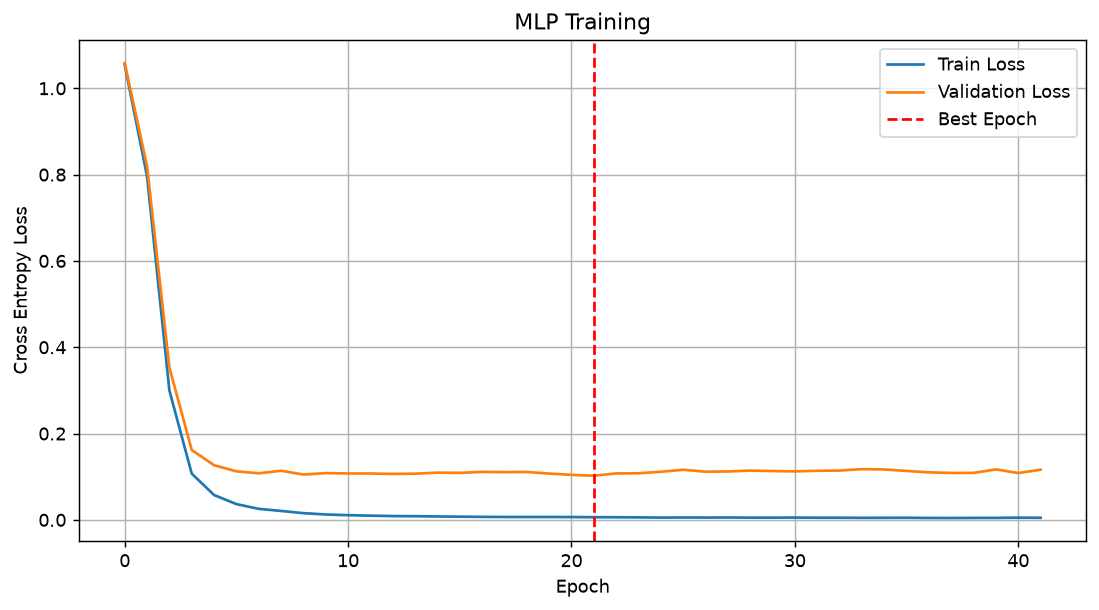


### Точность на валидации

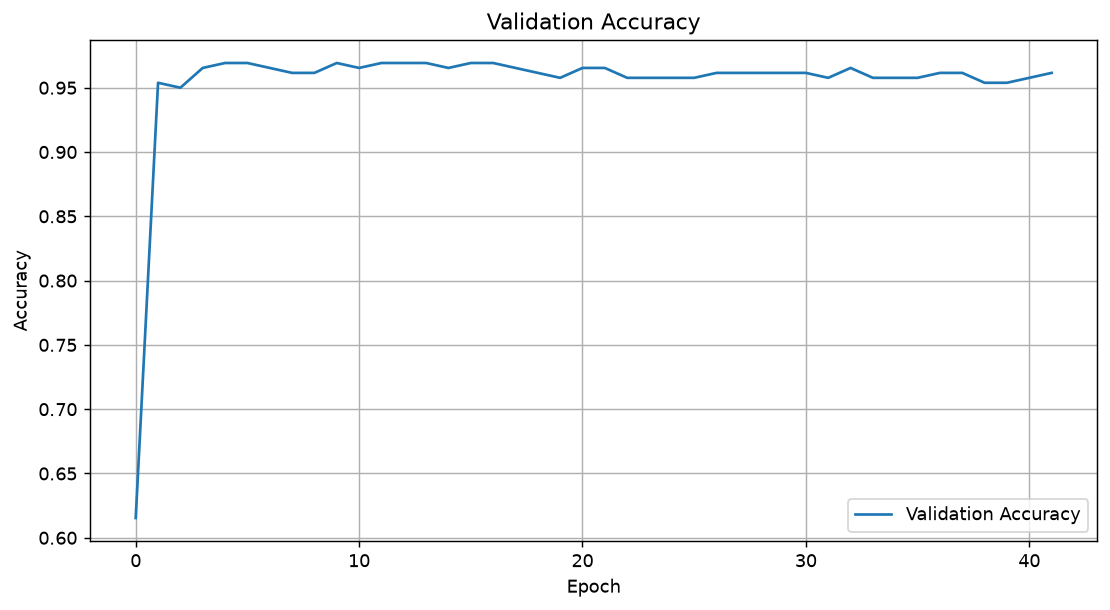


### Матрица ошибок

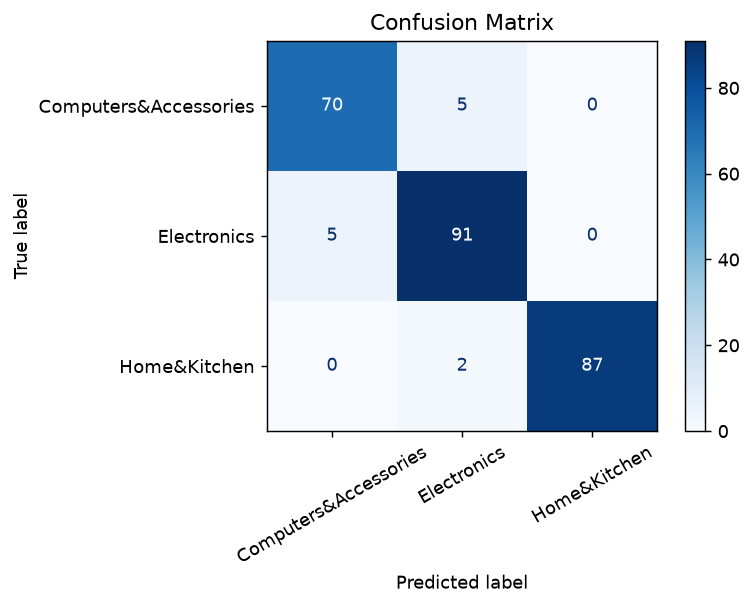


### ROC-кривые

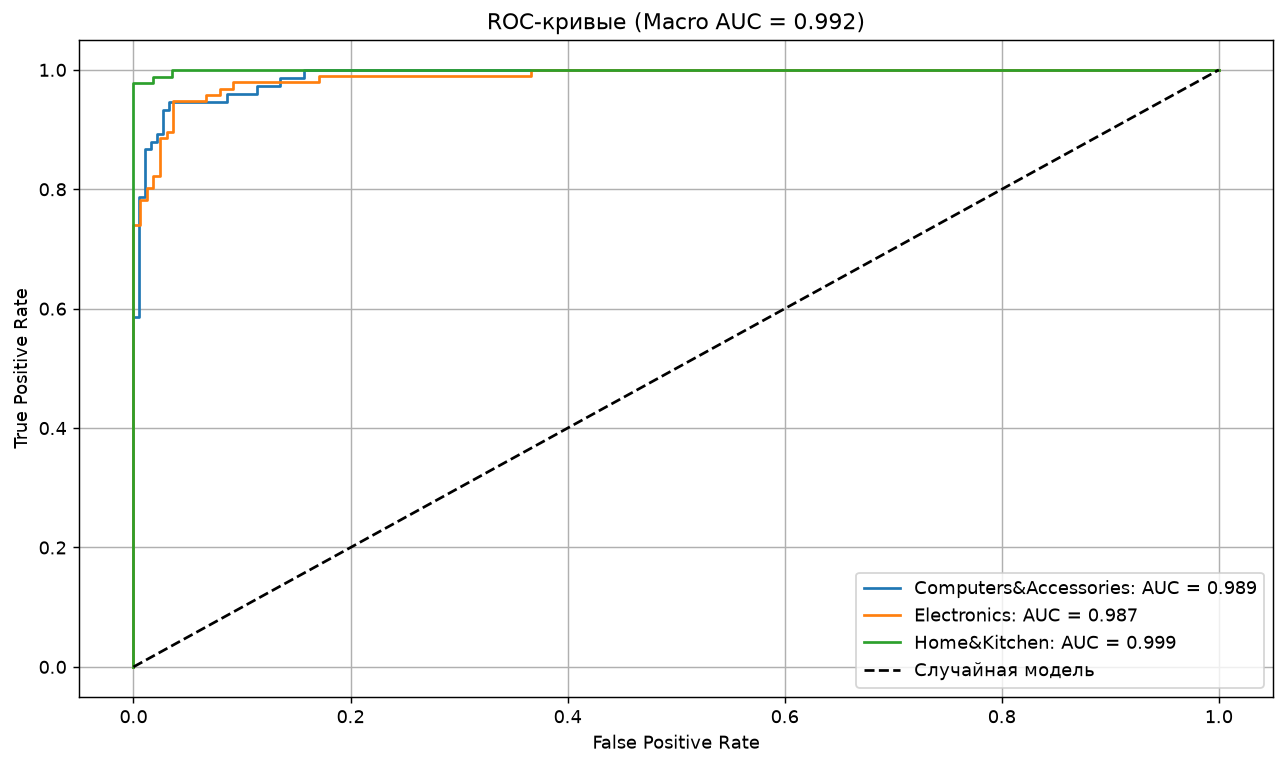


## Полный код


In [ ]:
import copy
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from torch import nn
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    auc
)
from sklearn.dummy import DummyClassifier


SEED = 42
EPOCHS = 200
BATCH_SIZE = 32
LEARNING_RATE = 0.001
PATIENCE = 20

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Устройство:", device)


csv_path = Path("amazon.csv")
if not csv_path.exists():
    csv_path = Path("upload") / "amazon.csv"
df = pd.read_csv(csv_path)

print("\nИсходный размер:", df.shape)

df = df[
    ["product_id", "product_name", "category"]
].dropna().copy()

#в category хранится длинная цепочка категорий, нужна только первая
df["main_category"] = (
    df["category"].str.split("|").str[0]
)

categories = [
    "Electronics",
    "Computers&Accessories",
    "Home&Kitchen"
]

df = df[
    df["main_category"].isin(categories)
].copy()

# Один и тот же товар может встречаться несколько раз, оставлыяем одну запись
df = df.drop_duplicates(subset="product_id")

# Одинаковые названия тоже убираем, иначе модель может увидеть
# одно название и в обучении, и в тесте
df = df.drop_duplicates(subset="product_name")

# уюираем пустые названия
df = df[df["product_name"].astype(str).str.strip() != ""]

print("\nПосле очистки:", df.shape)

print("\nРаспределение категорий:")
print(df["main_category"].value_counts())


# X — названия товаров
X = df["product_name"].astype(str).values

# y — названия категорий
y_text = df["main_category"].values

#превращаем категории в числа
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_text)

print("\nКлассы:")

for i, name in enumerate(label_encoder.classes_):
    print(i, "=", name)


X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.4,
    random_state=SEED,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    random_state=SEED,
    stratify=y_temp
)

print("\nРазмеры выборок:")
print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))


vectorizer = TfidfVectorizer(
    max_features=1000,
    ngram_range=(1, 2),
    lowercase=True
)

# мловарь TF-IDF строим только по обучающей части, иначе информация из теста попадёт в подготовку признаков
X_train_tfidf = vectorizer.fit_transform(X_train)

# Validation и Test преобразуем
# уже созданным словарём
X_val_tfidf = vectorizer.transform(X_val)
X_test_tfidf = vectorizer.transform(X_test)

print("\nКоличество признаков:",
      X_train_tfidf.shape[1])


# для сравнения берём простую модель она
# выбирает самый частый класс из обучающей выборки
baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(X_train_tfidf, y_train)

baseline_predictions = baseline.predict(X_test_tfidf)

baseline_accuracy = accuracy_score(
    y_test, baseline_predictions
)

baseline_f1 = f1_score(
    y_test,
    baseline_predictions,
    average="macro",
    zero_division=0
)

print("\nBASELINE")
print("Accuracy:", round(baseline_accuracy, 4))
print("Macro F1:", round(baseline_f1, 4))


train_x = torch.tensor(
    X_train_tfidf.toarray(),
    dtype=torch.float32
)

val_x = torch.tensor(
    X_val_tfidf.toarray(),
    dtype=torch.float32
)

test_x = torch.tensor(
    X_test_tfidf.toarray(),
    dtype=torch.float32
)

train_y = torch.tensor(
    y_train,
    dtype=torch.long
)

val_y = torch.tensor(
    y_val,
    dtype=torch.long
)

test_y = torch.tensor(
    y_test,
    dtype=torch.long
)

from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(train_x, train_y)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

train_x = train_x.to(device)
val_x = val_x.to(device)
test_x = test_x.to(device)

train_y = train_y.to(device)
val_y = val_y.to(device)
test_y = test_y.to(device)


input_size = X_train_tfidf.shape[1]
num_classes = len(label_encoder.classes_)

model = nn.Sequential(
    nn.Linear(input_size, 128),
    nn.ReLU(),
    nn.Dropout(0.2),

    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Dropout(0.2),

    nn.Linear(64, num_classes)
).to(device)

print("\nАРХИТЕКТУРА MLP")
print(model)

parameters = sum(
    p.numel() for p in model.parameters()
)

print("Количество параметров:", parameters)


optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0.001
)

loss_fn = nn.CrossEntropyLoss()


best_val_loss = float("inf")
best_epoch = 0
best_weights = copy.deepcopy(model.state_dict())

epochs_without_improvement = 0

train_history = []
val_history = []
accuracy_history = []


for epoch in range(EPOCHS):

    model.train()

    for batch_x, batch_y in train_loader:

        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad()

        predictions = model(batch_x)

        loss = loss_fn(predictions, batch_y)

        loss.backward()

        optimizer.step()

    # после каждой эпохи смотрим, как модель ведёт себя
    # на обучающей и проверочной выборках
    model.eval()

    with torch.no_grad():

        train_logits = model(train_x)
        val_logits = model(val_x)

        train_loss = loss_fn(
            train_logits, train_y
        ).item()

        val_loss = loss_fn(
            val_logits, val_y
        ).item()

        val_predictions = torch.argmax(
            val_logits, dim=1
        )

        val_accuracy = (
            (val_predictions == val_y)
            .float().mean().item()
        )

    train_history.append(train_loss)
    val_history.append(val_loss)
    accuracy_history.append(val_accuracy)

    # если на Validation ошибка стала меньше запомнаем эти веса
    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_epoch = epoch + 1

        best_weights = copy.deepcopy(
            model.state_dict()
        )

        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    if (epoch + 1) % 10 == 0:

        print(
            f"Epoch {epoch + 1:3d} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Accuracy: {val_accuracy:.4f}"
        )

    if epochs_without_improvement >= PATIENCE:
        print("\nEarly Stopping!")
        break


model.load_state_dict(best_weights)
model.eval()

print("\nЛучшая эпоха:", best_epoch)
print("Лучший Validation Loss:",
      round(best_val_loss, 5))


with torch.no_grad():

    test_logits = model(test_x)

    # Softmax превращает три выхода сети в вероятности классов.
    probabilities = torch.softmax(
        test_logits, dim=1
    ).cpu().numpy()

    test_predictions = np.argmax(
        probabilities, axis=1
    )

test_accuracy = accuracy_score(
    y_test, test_predictions
)

test_f1 = f1_score(
    y_test,
    test_predictions,
    average="macro",
    zero_division=0
)

print("\nTEST RESULTS")
print("MLP Accuracy:", round(test_accuracy, 4))
print("MLP Macro F1:", round(test_f1, 4))

print("\nCLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        test_predictions,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)


plt.figure(figsize=(10, 5))

plt.plot(
    train_history,
    label="Train Loss"
)

plt.plot(
    val_history,
    label="Validation Loss"
)

plt.axvline(
    best_epoch - 1,
    color="red",
    linestyle="--",
    label="Best Epoch"
)

plt.xlabel("Epoch")
plt.ylabel("Cross Entropy Loss")
plt.title("MLP Training")
plt.legend()
plt.grid()
plt.show()


plt.figure(figsize=(10, 5))

plt.plot(
    accuracy_history,
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Validation Accuracy")
plt.legend()
plt.grid()
plt.show()


cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=np.arange(num_classes)
)

print("\nМатрица ошибок:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
).plot(
    cmap="Blues",
    xticks_rotation=30
)

plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()


#три класса поэтому строим отдельную ROC-кривую
#один класс против двух остальных (One-vs-Rest).
y_test_binary = label_binarize(
    y_test,
    classes=np.arange(num_classes)
)

roc_auc_macro = roc_auc_score(
    y_test,
    probabilities,
    labels=np.arange(num_classes),
    multi_class="ovr",
    average="macro"
)

print("\nMacro ROC-AUC:", round(roc_auc_macro, 4))

plt.figure(figsize=(10, 6))

for i, category in enumerate(label_encoder.classes_):
    fpr, tpr, _ = roc_curve(
        y_test_binary[:, i],
        probabilities[:, i]
    )

    class_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{category}: AUC = {class_auc:.3f}"
    )

#дагональ показывает результат случайного ранжирования
plt.plot([0, 1], [0, 1], "k--", label="Случайная модель")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"ROC-кривые (Macro AUC = {roc_auc_macro:.3f})")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()


print("\nСРАВНЕНИЕ ")

print(
    f"Baseline Accuracy: {baseline_accuracy:.4f}"
)
print(
    f"MLP Accuracy:      {test_accuracy:.4f}"
)

print(
    f"Baseline Macro F1: {baseline_f1:.4f}"
)
print(
    f"MLP Macro F1:      {test_f1:.4f}"
)


def predict_product(product_name):

    #превращаем название в TF-IDF
    features = vectorizer.transform(
        [product_name]
    ).toarray()

    #превращаем в тензор
    x = torch.tensor(
        features,
        dtype=torch.float32
    ).to(device)

    model.eval()

    with torch.no_grad():

        logits = model(x)

        probs = torch.softmax(
            logits, dim=1
        )[0].cpu().numpy()

    class_index = np.argmax(probs)

    category = label_encoder.inverse_transform(
        [class_index]
    )[0]

    print("\nНовый товар:", product_name)
    print("Предсказанная категория:", category)

    print("\nВероятности:")

    for name, probability in zip(
        label_encoder.classes_, probs
    ):
        print(f"{name}: {probability:.2%}")


predict_product(
    "Wireless Bluetooth Headphones with Microphone"
)

predict_product(
    "USB C Cable for Laptop and Smartphone"
)

predict_product(
    "Non Stick Frying Pan for Kitchen Cooking"
)
